# Chore Completion Classifier

**Kaggle competition:** [chore-completion-classifier](https://www.kaggle.com/competitions/chore-completion-classifier) (private class competition)

## The task

Each photo shows one of two household chores: **washing dishes** or **taking out the trash**.
For every photo we must predict two things at the same time: the chore *and* whether it is finished.
So there are four possible labels:

| Label | Meaning |
|---|---|
| `Washing Dishes|Complete` | the dishes are clean |
| `Washing Dishes|Incomplete` | there are still dirty dishes |
| `Taking Out Trash|Complete` | the trash has been dealt with |
| `Taking Out Trash|Incomplete` | the trash is still full or overflowing |

- **Training set:** 66 labelled photos
- **Test set:** 36 photos without labels
- **Metric:** macro-average F1 score. This means the F1 score is calculated for each of the four classes and then averaged, so every class is equally important, even the small ones.
- **Submission:** a CSV file with the columns `id,label`

## Our plan

66 photos are far too few to train an image model from scratch. Instead, we use **CLIP**, a large model that has already
learned from hundreds of millions of image–caption pairs. We use it in two ways:

1. **Zero-shot:** we describe each class in words and let CLIP choose the description that fits the photo best. This needs no training at all.
2. **Linear probe:** we turn each photo into a list of numbers with CLIP (an *embedding*) and train a small logistic regression model on our 66 labelled photos.

At the end we combine both. The notebook is divided into phases:

| Phase | What happens |
|---|---|
| 1 | Setup: libraries, paths and settings |
| 2 | Load the data and check it |
| 3 | Explore and visualise the data |
| 4 | Turn the images into CLIP embeddings |
| 5 | Baseline: zero-shot classification |
| 6 | Linear probe and model comparison with cross-validation |
| 7 | Error analysis |
| 8 | Train the final model and create the submission |
| 9 | Summary and next steps |

---
# Phase 1 – Setup

In this phase we import the libraries we need and define the paths and the settings that are used in the whole notebook.

**Libraries:**
- `pandas` and `numpy` for tables and numbers
- `matplotlib` and `PIL` (Pillow) to show images and charts
- `torch` and `open_clip` to run the CLIP models
- `scikit-learn` for logistic regression, cross-validation and the F1 score

If something is missing, install it with:
`pip install torch torchvision open_clip_torch scikit-learn pandas pillow matplotlib`

In [1]:
import warnings
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageOps
from scipy.special import softmax
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, f1_score
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 60)

ROOT = Path.cwd()                      # run the notebook from the competition folder
DATA_DIR = ROOT / "data"
IMG_DIR = DATA_DIR / "images"
FEAT_DIR = ROOT / "features"           # CLIP embeddings are saved here, so we compute them only once
IMG_DIR.mkdir(parents=True, exist_ok=True)
FEAT_DIR.mkdir(exist_ok=True)

DEVICE = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
SEED = 0

CLASSES = [
    "Washing Dishes|Complete",
    "Washing Dishes|Incomplete",
    "Taking Out Trash|Complete",
    "Taking Out Trash|Incomplete",
]
SHORT = ["Dishes ✓", "Dishes ✗", "Trash ✓", "Trash ✗"]   # short names for charts

print("Device:", DEVICE)

Device: mps


---
# Phase 2 – Load the data

The competition gives us three small CSV files: `train.csv`, `test.csv` and `sample_submission.csv`.
The photos themselves are not inside the CSV files. Each row only has a link (`image_url`) to the photo,
which is stored in a public GitHub repository.

In this phase we:
1. read the CSV files,
2. check that the IDs are complete and do not overlap,
3. download any photos that are not on our computer yet.

In [2]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

print("Train:", train.shape, " Test:", test.shape)
train.head()

Train: (66, 4)  Test: (36, 3)


,id,image_file,image_url,label
0,1,image_001.jpg,https://raw.githubusercontent.com/elijahzins/chore-image...,Washing Dishes|Complete
1,2,image_002.jpg,https://raw.githubusercontent.com/elijahzins/chore-image...,Washing Dishes|Incomplete
2,7,image_007.jpg,https://raw.githubusercontent.com/elijahzins/chore-image...,Washing Dishes|Complete
3,8,image_008.jpg,https://raw.githubusercontent.com/elijahzins/chore-image...,Washing Dishes|Incomplete
4,9,image_009.jpg,https://raw.githubusercontent.com/elijahzins/chore-image...,Taking Out Trash|Complete


**Sanity checks.** The training and test IDs should not overlap, and together they should cover all 102 photos.
Every label must also be one of our four classes.

In [3]:
assert not set(train.id) & set(test.id), "train and test IDs overlap"
assert set(train.id) | set(test.id) == set(range(1, 103)), "some IDs are missing"
assert train.label.isin(CLASSES).all(), "unknown label found"
print("All checks passed ✓")

All checks passed ✓


**Download the photos.** We only download a photo if it is not already in `data/images/`, so this cell is fast the second time.

In [4]:
all_rows = pd.concat([train, test])
missing = [r for r in all_rows.itertuples() if not (IMG_DIR / r.image_file).exists()]
for r in missing:
    urlretrieve(r.image_url, IMG_DIR / r.image_file)
print(f"Downloaded {len(missing)} new photos. Photos on disk: {len(list(IMG_DIR.glob('*.jpg')))}")

def load_image(image_id, max_side=None):
    """Open a photo, rotate it correctly (EXIF) and convert it to RGB."""
    im = ImageOps.exif_transpose(Image.open(IMG_DIR / f"image_{image_id:03d}.jpg")).convert("RGB")
    if max_side:
        im.thumbnail((max_side, max_side))
    return im

Downloaded 0 new photos. Photos on disk: 102


---
# Phase 3 – Explore and visualise the data

Before we build a model, we look at the data. We want to answer three questions:

1. **How many photos does each class have?** If one class is much smaller, the model may ignore it.
2. **What do the photos look like?** This tells us what "complete" and "incomplete" really mean in this dataset.
3. **How big are the photos?** CLIP shrinks every photo to a small square, so small details can get lost.

### 3.1 Class distribution

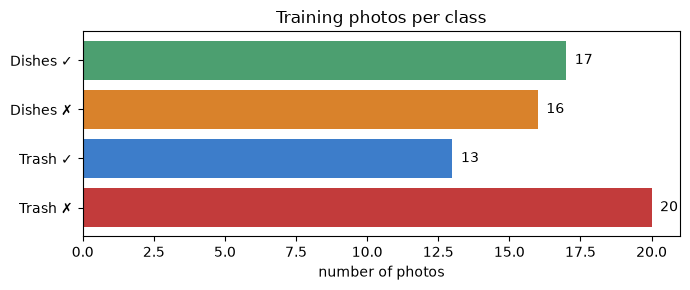

,count,share
label,,
Washing Dishes|Complete,17,0.26
Washing Dishes|Incomplete,16,0.24
Taking Out Trash|Complete,13,0.20
Taking Out Trash|Incomplete,20,0.30


In [5]:
counts = train.label.value_counts().reindex(CLASSES)
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(SHORT, counts.values, color=["#4C9F70", "#D9822B", "#3D7DCA", "#C23B3B"])
for i, v in enumerate(counts.values):
    ax.text(v + 0.3, i, str(v), va="center")
ax.invert_yaxis(); ax.set_xlabel("number of photos"); ax.set_title("Training photos per class")
plt.tight_layout(); plt.show()
counts.to_frame("count").assign(share=lambda d: (d["count"] / d["count"].sum()).round(2))

The classes are **slightly imbalanced**: the largest class (Trash ✗, 20 photos) is about 1.5 times bigger than
the smallest (Trash ✓, 13 photos). This is the reason the competition uses *macro* F1. Later we will use
`class_weight="balanced"` so that the model pays the same attention to every class.

### 3.2 Example photos from each class


Washing Dishes|Complete


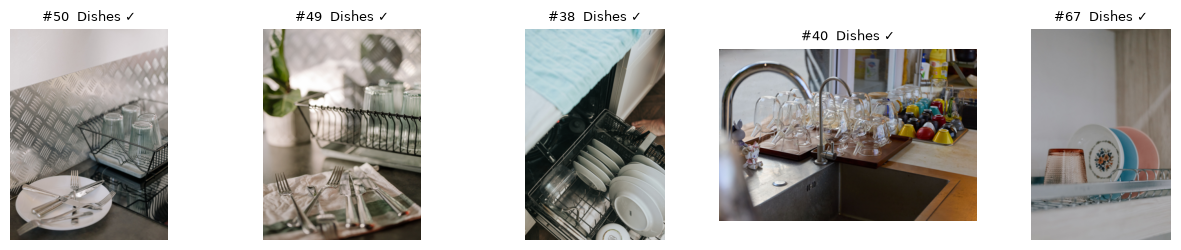


Washing Dishes|Incomplete


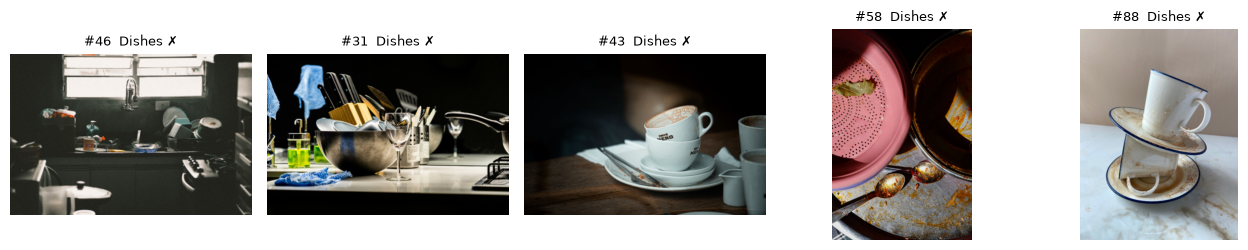


Taking Out Trash|Complete


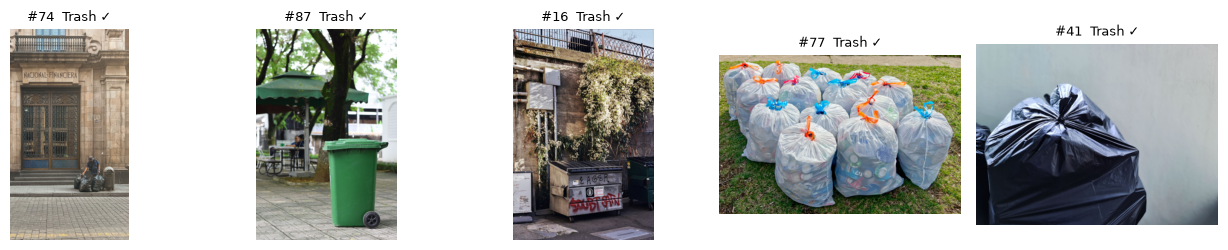


Taking Out Trash|Incomplete


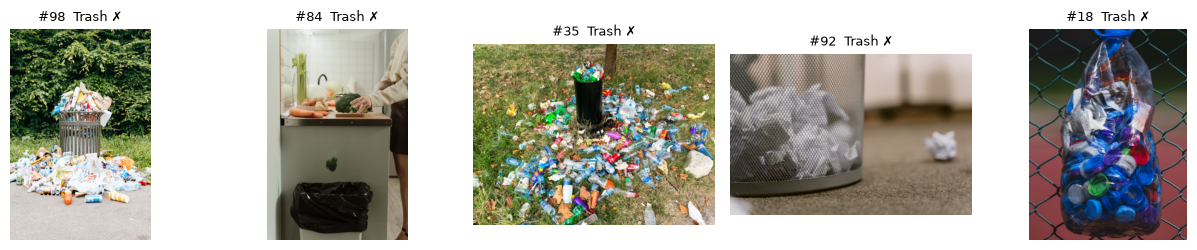

In [6]:
def show_grid(ids, titles, ncols=5, size=2.6):
    nrows = int(np.ceil(len(ids) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, i, t in zip(np.ravel(axes), ids, titles):
        ax.imshow(load_image(i, 400)); ax.set_title(t, fontsize=9)
    plt.tight_layout(); plt.show()

rng = np.random.default_rng(SEED)
for cls, short in zip(CLASSES, SHORT):
    ids = rng.choice(train.id[train.label == cls].values, 5, replace=False)
    print(f"\n{cls}")
    show_grid(ids, [f"#{i}  {short}" for i in ids])

**What we learn from the photos:**

- **Dishes ✓** – clean plates on a drying rack, a clean empty sink, clean dishes in a dishwasher.
- **Dishes ✗** – plates with leftover food, dirty cups after a meal, and sometimes just *one* used plate in the sink, or someone who is *still* washing.
- **Trash ✓** – not only empty bins! Bins lined up at the street, closed dumpsters, tied-up bags and sorted recycling also count as "complete".
- **Trash ✗** – overflowing bins and litter on the ground.

So the difference between **complete** and **incomplete** is often a small detail. Telling dishes from trash is
easy, but telling *clean* from *dirty* is the real challenge. We use these observations when we write
the text descriptions (prompts) in Phase 4.

### 3.3 Photo sizes

In [7]:
sizes = pd.DataFrame([Image.open(IMG_DIR / f).size for f in all_rows.image_file], columns=["width", "height"])
sizes.describe().loc[["min", "50%", "max"]].astype(int)

,width,height
min,1835,2043
50%,4160,4032
max,8368,9660


The photos are large (often several thousand pixels wide), but CLIP looks at them at only 224×224 or 384×384 pixels.
To keep more detail, in Phase 4 we also give the model **five zoomed-in crops** of each photo.

---
# Phase 4 – Turn the images into CLIP embeddings

### What is CLIP?

CLIP is a pair of neural networks that were trained together on a very large number of images and their captions:

- the **image encoder** turns a photo into a vector (a list of numbers, for example 1024 numbers),
- the **text encoder** turns a sentence into a vector of the same length.

During training, CLIP learned to put a photo and its matching caption **close together**. Because of this,
the vectors describe the *meaning* of the photo ("a sink full of dirty dishes"), not just its colours.
We do **not** retrain CLIP. We only use it to read the photos.

### Which CLIP models?

We compare several pre-trained models from the `open_clip` library. Bigger models trained on more data usually work better
when we have very little data of our own.

In [8]:
MODELS = {
    # name in this notebook : (architecture, pre-trained weights)
    "vitl14_openai": ("ViT-L-14", "openai"),                  # original OpenAI CLIP, ~400M image-text pairs
    "vith14_laion":  ("ViT-H-14", "laion2b_s32b_b79k"),       # OpenCLIP, LAION-2B dataset
    "siglip_so400m": ("ViT-SO400M-14-SigLIP-384", "webli"),   # Google SigLIP, sees images at 384×384
    # "vitbigg_laion": ("ViT-bigG-14", "laion2b_s39b_b160k"),   # the largest OpenCLIP model
    "eva02_l":       ("EVA02-L-14-336", "merged2b_s6b_b61k"),  # EVA-02, sees images at 336×336
}

### Seven views of each photo

For every photo we create **7 views** and encode each of them:

1. the full photo,
2. the full photo flipped left–right (a mirror image is still the same chore),
3. – 7. five crops: the four corners (each 2/3 of the photo) and the centre.

The crops act like a magnifying glass: they help the model see small details such as food left on a plate.

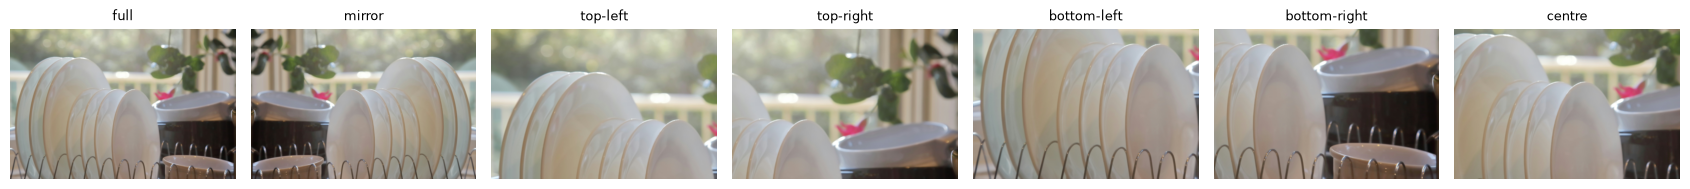

In [9]:
def make_views(im):
    w, h = im.size
    cw, ch = int(w * 2 / 3), int(h * 2 / 3)
    corners = [(0, 0), (w - cw, 0), (0, h - ch), (w - cw, h - ch), ((w - cw) // 2, (h - ch) // 2)]
    return [im, ImageOps.mirror(im)] + [im.crop((x, y, x + cw, y + ch)) for x, y in corners]

example = make_views(load_image(train.id.iloc[0], 600))
names = ["full", "mirror", "top-left", "top-right", "bottom-left", "bottom-right", "centre"]
fig, axes = plt.subplots(1, 7, figsize=(17, 2.8))
for ax, v, n in zip(axes, example, names):
    ax.imshow(v); ax.set_title(n, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

### Text descriptions (prompts)

For the zero-shot part we write **six short descriptions per class**. CLIP turns every description into a vector,
and we average the six vectors to get one "class vector". We wrote the prompts *after* looking at the training photos
in Phase 3. For example, "tied-up garbage bags ready for pickup" counts as **Trash ✓**.

In [10]:
PROMPTS = {
    "Washing Dishes|Complete": [
        "a photo of clean dishes drying on a rack",
        "a photo of a clean empty kitchen sink",
        "a photo of clean plates and cups neatly stacked",
        "a photo of clean dishes in an open dishwasher",
        "a photo of a spotless tidy kitchen counter",
        "a photo of shiny clean plates",
    ],
    "Washing Dishes|Incomplete": [
        "a photo of a sink full of dirty dishes",
        "a photo of a dirty plate with leftover food",
        "a photo of a used plate and fork left in the sink",
        "a photo of someone washing a dirty plate under the tap",
        "a photo of dirty cups and dishes left after a meal",
        "a photo of a cluttered kitchen with unwashed dishes",
    ],
    "Taking Out Trash|Complete": [
        "a photo of garbage bins lined up at the curb for collection",
        "a photo of closed dumpsters in an alley",
        "a photo of tied-up garbage bags ready for pickup",
        "a photo of sorted recycling in separate bins",
        "a photo of a neat trash area with closed lids",
        "a photo of an empty trash can",
    ],
    "Taking Out Trash|Incomplete": [
        "a photo of an overflowing trash can",
        "a photo of litter scattered on the ground around a bin",
        "a photo of a garbage bin overflowing with rubbish",
        "a photo of a messy pile of trash",
        "a photo of a dumpster overflowing with junk",
        "a photo of garbage spilling onto the street",
    ],
}

### Compute the embeddings (or load them from disk)

Running the big models takes a few minutes per model, so we save the results in `features/<model>.npz`.
If the file already exists, we simply load it. Delete the `features/` folder if you change the prompts or the views.

Each file contains:
- `img`, `img_flip`: embeddings of the full photo and its mirror image, shape `(102, D)`
- `crops`: embeddings of the five crops, shape `(102, 5, D)`
- `txt`: one vector per class from the prompts, shape `(4, D)`

All vectors are normalised to length 1, so the dot product of two vectors is their *cosine similarity*.

In [11]:
import open_clip

def unit(a):
    return a / np.linalg.norm(a, axis=-1, keepdims=True)

@torch.no_grad()
def extract(name):
    arch, pretrained = MODELS[name]
    print(f"[{name}] loading {arch} ({pretrained}) on {DEVICE}")
    model, _, preprocess = open_clip.create_model_and_transforms(arch, pretrained=pretrained)
    model = model.to(DEVICE).eval()
    tokenizer = open_clip.get_tokenizer(arch)
    print(f"[{name}] model loaded")

    ids = sorted(all_rows.id)
    file_of = dict(zip(all_rows.id, all_rows.image_file))
    n = len(ids)
    feats = []
    for k, i in enumerate(ids, start=1):
        print(f"[{name}] image {k}/{n}  id={i}  file={file_of[i]}", flush=True)
        batch = torch.stack([preprocess(v) for v in make_views(load_image(i, 1536))]).to(DEVICE)
        f = model.encode_image(batch).float()
        feats.append((f / f.norm(dim=-1, keepdim=True)).cpu().numpy())

    print(f"[{name}] encoding text prompts for {len(CLASSES)} classes")
    txt = []
    for c in CLASSES:
        t = model.encode_text(tokenizer(PROMPTS[c]).to(DEVICE)).float()
        txt.append((t / t.norm(dim=-1, keepdim=True)).mean(0))
        print(f"[{name}] prompts done: {c}")

    feats = np.array(feats)
    out = FEAT_DIR / f"{name}.npz"
    np.savez(out, ids=np.array(ids), img=feats[:, 0], img_flip=feats[:, 1],
             crops=feats[:, 2:], txt=torch.stack(txt).cpu().numpy())
    print(f"[{name}] saved {out.name}  img {feats.shape}")
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print(f"Models to check: {list(MODELS)}")
for name in MODELS:
    path = FEAT_DIR / f"{name}.npz"
    if path.exists():
        print(f"[{name}] already on disk, skipping")
        continue
    print(f"[{name}] extracting ...")
    extract(name)
    print(f"[{name}] finished")
print("Embeddings ready:", sorted(p.stem for p in FEAT_DIR.glob("*.npz")))

Models to check: ['vitl14_openai', 'vith14_laion', 'siglip_so400m', 'eva02_l']
[vitl14_openai] already on disk, skipping
[vith14_laion] already on disk, skipping
[siglip_so400m] already on disk, skipping
[eva02_l] extracting ...
[eva02_l] loading EVA02-L-14-336 (merged2b_s6b_b61k) on mps
[eva02_l] model loaded
[eva02_l] image 1/102  id=1  file=image_001.jpg
[eva02_l] image 2/102  id=2  file=image_002.jpg
[eva02_l] image 3/102  id=3  file=image_003.jpg
[eva02_l] image 4/102  id=4  file=image_004.jpg
[eva02_l] image 5/102  id=5  file=image_005.jpg
[eva02_l] image 6/102  id=6  file=image_006.jpg
[eva02_l] image 7/102  id=7  file=image_007.jpg
[eva02_l] image 8/102  id=8  file=image_008.jpg
[eva02_l] image 9/102  id=9  file=image_009.jpg
[eva02_l] image 10/102  id=10  file=image_010.jpg
[eva02_l] image 11/102  id=11  file=image_011.jpg
[eva02_l] image 12/102  id=12  file=image_012.jpg
[eva02_l] image 13/102  id=13  file=image_013.jpg
[eva02_l] image 14/102  id=14  file=image_014.jpg
[eva02

### Image-only features: DINOv2

CLIP learned from captions, so it mostly recognises the *scene* ("garbage", "kitchen"). The errors in Phase 7 are about
small details: a tied bag versus loose litter, coffee stains in a cup. **DINOv2** (Meta) learned from images only, without
text, and is known to keep more of these fine details.

We encode the same 7 views with DINOv2 ViT-L/14 at 448×448. For every view we keep two vectors and put them side by side:
- the **CLS token**, a summary of the whole view,
- the **average of the patch tokens**, which keeps more local detail.

DINOv2 has no text encoder, so it has no zero-shot part. It is only used in the linear probe.

In [ ]:
import timm

IMAGE_MODELS = {
    # name in this notebook : timm model name
    "dinov2_l": "vit_large_patch14_dinov2.lvd142m",
}
DINO_SIZE = 448        # must be a multiple of the 14-pixel patch size

@torch.no_grad()
def extract_image_only(name):
    print(f"[{name}] loading {IMAGE_MODELS[name]} on {DEVICE}")
    model = timm.create_model(IMAGE_MODELS[name], pretrained=True, num_classes=0, img_size=DINO_SIZE)
    model = model.to(DEVICE).eval()
    cfg = timm.data.resolve_data_config({"input_size": (3, DINO_SIZE, DINO_SIZE)}, model=model)
    preprocess = timm.data.create_transform(**cfg)

    ids = sorted(all_rows.id)
    feats = []
    for k, i in enumerate(ids, start=1):
        batch = torch.stack([preprocess(v) for v in make_views(load_image(i, 1536))]).to(DEVICE)
        tokens = model.forward_features(batch).float()
        cls = unit(tokens[:, 0].cpu().numpy())
        patches = unit(tokens[:, model.num_prefix_tokens:].mean(1).cpu().numpy())
        feats.append(unit(np.hstack([cls, patches])))
        if k % 20 == 0 or k == len(ids):
            print(f"[{name}] image {k}/{len(ids)}", flush=True)

    feats = np.array(feats)
    out = FEAT_DIR / f"{name}.npz"
    np.savez(out, ids=np.array(ids), img=feats[:, 0], img_flip=feats[:, 1], crops=feats[:, 2:])
    print(f"[{name}] saved {out.name}  img {feats.shape}")
    del model

for name in IMAGE_MODELS:
    if (FEAT_DIR / f"{name}.npz").exists():
        print(f"[{name}] already on disk, skipping")
    else:
        extract_image_only(name)

ALL_MODELS = list(MODELS) + list(IMAGE_MODELS)
print("All models:", ALL_MODELS)

Now we load the embeddings into one dictionary. For every model and every split (train / test) we prepare
three **feature modes**, which we compare in Phase 6:

| Mode | Features for one photo |
|---|---|
| `full` | full photo and mirror photo, used as two separate training examples |
| `mean7` | the average of all 7 views (one vector) |
| `concat` | the average of full+mirror, *next to* the average of the 5 crops (twice as long) |

We also compute the **zero-shot probabilities**: the cosine similarity between a photo and each class vector,
multiplied by 100 and passed through a softmax so that the four numbers add up to 1.

In [12]:
y = train.label.map(CLASSES.index).values      # labels as numbers 0–3

def load_features(name):
    z = np.load(FEAT_DIR / f"{name}.npz")
    pos = {i: k for k, i in enumerate(z["ids"])}
    out = {}
    for split, df in (("tr", train), ("te", test)):
        idx = [pos[i] for i in df.id]
        full, flip, crops = z["img"][idx], z["img_flip"][idx], z["crops"][idx]
        both = unit(full + flip)
        mean7 = unit(full + flip + crops.sum(1))
        out[split] = {"full": (full, flip), "mean7": (mean7,),
                      "concat": (np.hstack([both, unit(crops.mean(1))]),)}
        if "txt" in z:                             # image-only models (DINOv2) have no zero-shot part
            out[split + "_zs"] = {"full": softmax(100 * both @ z["txt"].T, axis=1),
                                  "mean7": softmax(100 * mean7 @ z["txt"].T, axis=1)}
    return out

FEATS = {name: load_features(name) for name in ALL_MODELS}
print({n: FEATS[n]["tr"]["mean7"][0].shape for n in ALL_MODELS})

{'vitl14_openai': (66, 768), 'vith14_laion': (66, 1024), 'siglip_so400m': (66, 1152), 'eva02_l': (66, 768)}


---
# Phase 5 – Baseline: zero-shot classification

Zero-shot means **no training**. For each photo we simply pick the class whose description is most similar.
Because nothing is learned from the labels, we can measure the score on all 66 training photos directly.
This gives us a first **baseline**: every model we train later must beat it.

In [13]:
zs_rows = []
for name in MODELS:
    for mode in ("full", "mean7"):
        pred = FEATS[name]["tr_zs"][mode].argmax(1)
        zs_rows.append({"model": name, "views": mode, "macro_F1": f1_score(y, pred, average="macro"),
                        "accuracy": (pred == y).mean()})
zs_table = pd.DataFrame(zs_rows).sort_values("macro_F1", ascending=False).round(3)
zs_table

,model,views,macro_F1,accuracy
4,siglip_so400m,full,0.830,0.848
2,vith14_laion,full,0.828,0.833
6,eva02_l,full,0.810,0.833
5,siglip_so400m,mean7,0.809,0.833
3,vith14_laion,mean7,0.797,0.803
1,vitl14_openai,mean7,0.797,0.803
0,vitl14_openai,full,0.785,0.788
7,eva02_l,mean7,0.781,0.803


**How to read this:** `views = full` uses only the full photo, and `mean7` also uses the five crops.
The zero-shot scores show how much CLIP "understands" the task out of the box. They are a good start,
but our own 66 labelled photos should help the model learn what *this* dataset means by "complete".

---
# Phase 6 – Linear probe and model comparison

### The idea

A **linear probe** is a logistic regression trained on top of the frozen CLIP embeddings. It learns, for every class,
a weighted sum of the embedding numbers. It is a very simple model, and that is good here: with only 66 photos, a more
flexible model would simply memorise the training photos.

We also try a **blend**: the final probability is
`(1 − w) × linear probe + w × zero-shot`.
The zero-shot part adds general knowledge from the prompts, while the linear probe adds what we learn from our labels.

Important settings:
- `C` controls regularisation. Small `C` = a simpler model; large `C` = the model follows the training data more closely.
- `class_weight="balanced"` gives the smaller classes more weight, which suits the macro F1 metric.

### How we measure: repeated cross-validation

We cannot use the test set to choose a model, because we do not have its labels. Instead, we use
**5-fold cross-validation, repeated 10 times**: the 66 photos are split into 5 parts, we train on 4 parts and
test on the 5th, and we do this for every part and with 10 different random splits. The average of these
50 scores is a much more stable estimate than one single split.

*Note:* the Kaggle leaderboard uses only part of the 36 test photos, so one wrong photo changes the score a lot.
Cross-validation is a more reliable guide than the leaderboard.

In [14]:
def predict(cfg, tr_idx, te_split="tr", te_idx=None):
    """Train on the training rows tr_idx and return class probabilities for te_split[te_idx]."""
    names, mode, C, w = cfg["models"], cfg["mode"], cfg["C"], cfg["w"]
    zs_mode = "full" if mode == "full" else "mean7"
    sel = (lambda a: a) if te_idx is None else (lambda a: a[te_idx])
    zs_names = [n for n in names if "tr_zs" in FEATS[n]]
    if not zs_names:                               # only image-only models: no zero-shot to blend
        w = 0.0
    else:
        zs = sel(np.mean([FEATS[n][te_split + "_zs"][zs_mode] for n in zs_names], axis=0))
    if w == 1.0:                                   # pure zero-shot
        return zs
    def views(split):                              # stack the features of several models side by side
        return [np.hstack(v) for v in zip(*[FEATS[n][split][mode] for n in names])]
    tr_views = views("tr")
    X = np.vstack([v[tr_idx] for v in tr_views])
    Y = np.concatenate([y[tr_idx]] * len(tr_views))
    clf = LogisticRegression(C=C, max_iter=5000, class_weight="balanced").fit(X, Y)
    p = np.mean([clf.predict_proba(sel(v)) for v in views(te_split)], axis=0)
    return p if w == 0.0 else (1 - w) * p + w * zs

SPLITS = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED).split(np.zeros(len(y)), y))

def cv_score(cfg):
    scores = [f1_score(y[va], predict(cfg, tr, "tr", va).argmax(1), average="macro") for tr, va in SPLITS]
    return np.mean(scores), np.std(scores)

### Step 6.1 – Which CLIP model is best?

First we compare the models with the same simple settings (linear probe on all 7 views, `C=3`, no blend).

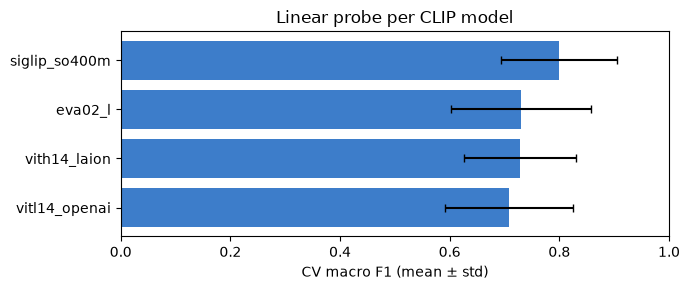

,model,cv_macro_F1,std
2,siglip_so400m,0.799,0.106
3,eva02_l,0.730,0.128
1,vith14_laion,0.729,0.102
0,vitl14_openai,0.708,0.116


In [15]:
rows = []
for name in ALL_MODELS:
    m, s = cv_score({"models": [name], "mode": "mean7", "C": 3, "w": 0.0})
    rows.append({"model": name, "cv_macro_F1": m, "std": s})
model_table = pd.DataFrame(rows).sort_values("cv_macro_F1", ascending=False).round(3)

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(model_table.model, model_table.cv_macro_F1, xerr=model_table["std"], color="#3D7DCA", capsize=3)
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel("CV macro F1 (mean ± std)")
ax.set_title("Linear probe per CLIP model"); plt.tight_layout(); plt.show()
model_table

### Step 6.2 – Tune the settings

Now we take the models and try the different feature modes, values of `C`, blend weights `w`,
and pairs of models. This is a small grid search. It takes a few minutes.

In [16]:
import itertools

top_models = list(model_table.model[:4])
model_sets = [[m] for m in top_models] + [list(p) for p in itertools.combinations(top_models, 2)]

grid = []
for names, mode, C, w in itertools.product(model_sets, ["full", "mean7", "concat"], [1, 3, 10], [0.0, 0.3, 0.5]):
    cfg = {"models": names, "mode": mode, "C": C, "w": w}
    m, s = cv_score(cfg)
    grid.append({**cfg, "models": " + ".join(names), "cv_macro_F1": m, "std": s})
grid = pd.DataFrame(grid).sort_values("cv_macro_F1", ascending=False).reset_index(drop=True)
grid.head(15).round(3)

,models,mode,C,w,cv_macro_F1,std
0,eva02_l + vith14_laion,full,1,0.5,0.855,0.103
1,vith14_laion,mean7,1,0.3,0.847,0.111
2,siglip_so400m + eva02_l,full,3,0.3,0.847,0.121
3,vith14_laion,concat,1,0.5,0.844,0.112
4,vith14_laion,full,3,0.3,0.841,0.092
5,siglip_so400m,full,10,0.3,0.841,0.117
6,vith14_laion,concat,3,0.5,0.840,0.114
7,vith14_laion,full,10,0.5,0.840,0.104
8,eva02_l + vith14_laion,full,3,0.5,0.840,0.101
9,siglip_so400m + vith14_laion,full,3,0.3,0.839,0.123


**How to read the table:** each row is one setting. Higher `cv_macro_F1` is better. The `std` column shows how much the
score changes between the 50 splits. With only 66 photos it is large, so differences of 0.01–0.02 are **not**
meaningful. That is why we prefer settings that are both near the top **and** simple.

Best setting: {'models': ['eva02_l', 'vith14_laion'], 'mode': 'full', 'C': 1.0, 'w': 0.5}
CV macro F1: 0.855 ± 0.103


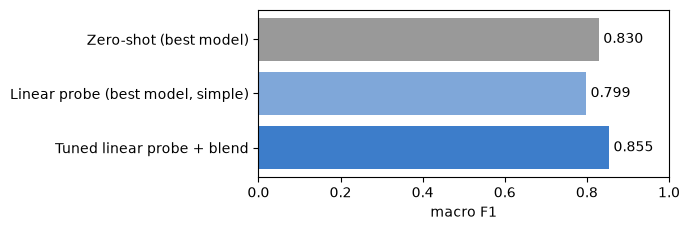

In [17]:
best = grid.iloc[0]
BEST_CFG = {"models": best.models.split(" + "), "mode": best["mode"], "C": float(best.C), "w": float(best.w)}
print("Best setting:", BEST_CFG)
print(f"CV macro F1: {best.cv_macro_F1:.3f} ± {best['std']:.3f}")

summary = pd.DataFrame([
    {"approach": "Zero-shot (best model)", "macro_F1": zs_table.macro_F1.max()},
    {"approach": "Linear probe (best model, simple)", "macro_F1": model_table.cv_macro_F1.max()},
    {"approach": "Tuned linear probe + blend", "macro_F1": best.cv_macro_F1},
])
fig, ax = plt.subplots(figsize=(7, 2.4))
ax.barh(summary.approach, summary.macro_F1, color=["#999999", "#7FA7D9", "#3D7DCA"])
for i, v in enumerate(summary.macro_F1):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center")
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel("macro F1"); plt.tight_layout(); plt.show()

---
# Phase 7 – Error analysis

A single score does not tell us *where* the model fails. Here we create **out-of-fold predictions**: every training photo
is predicted by a model that did not see it during training. Then we look at the confusion matrix and at the photos
that were classified wrongly.

Out-of-fold macro F1: 0.871


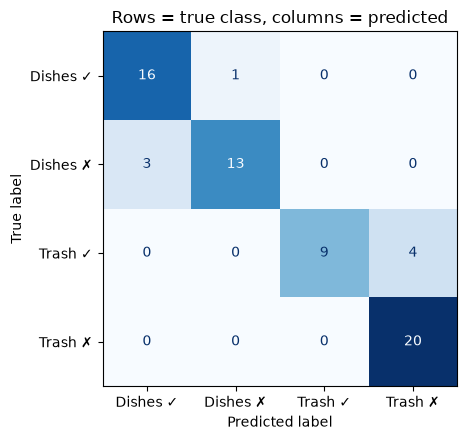

In [18]:
oof = np.zeros((len(y), 4))
for tr, va in StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(np.zeros(len(y)), y):
    oof[va] = predict(BEST_CFG, tr, "tr", va)
oof_pred = oof.argmax(1)
print(f"Out-of-fold macro F1: {f1_score(y, oof_pred, average='macro'):.3f}")

fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y, oof_pred), display_labels=SHORT).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Rows = true class, columns = predicted"); plt.tight_layout(); plt.show()

**How to read the matrix:** the diagonal shows correct predictions. Any number outside the diagonal is a mistake.
Look at which blocks the mistakes fall in: confusing *dishes* with *trash* would be a serious problem, while confusing
*complete* with *incomplete* within the same chore is the hard part of this task.

8 wrong out of 66


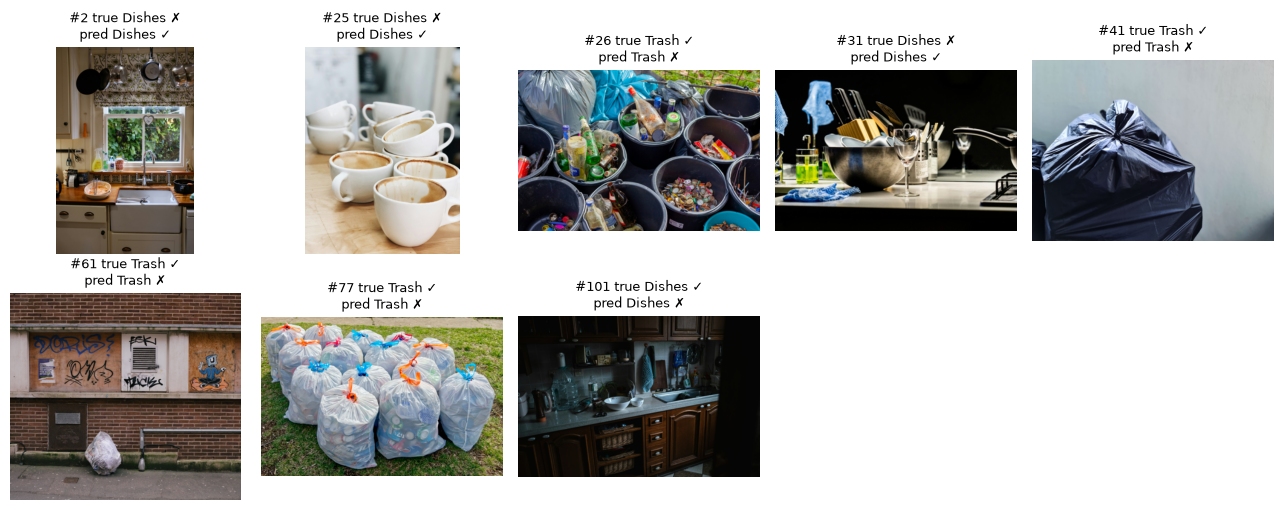

In [19]:
wrong = np.where(oof_pred != y)[0]
print(f"{len(wrong)} wrong out of {len(y)}")
if len(wrong):
    show_grid(train.id.values[wrong],
              [f"#{train.id.values[i]} true {SHORT[y[i]]}\npred {SHORT[oof_pred[i]]}" for i in wrong])

Some of these mistakes are understandable even for a person. For example, a single plate in a sink, or a closed
black bag that could be "full" or "ready to be taken out". With such a small dataset some label noise is normal, so
we should not expect a perfect score.

---
# Phase 8 – Train the final model and create the submission

Now we train the best setting on **all 66** training photos (no cross-validation) and predict the 36 test photos.
Then we check that the file has the correct format before we save it.

In [20]:
proba = predict(BEST_CFG, np.arange(len(y)), te_split="te")
submission = pd.DataFrame({"id": test.id, "label": [CLASSES[k] for k in proba.argmax(1)]})

assert len(submission) == 36 and submission.id.is_unique and set(submission.id) == set(test.id)
assert submission.label.isin(CLASSES).all()
submission.to_csv(ROOT / "submission.csv", index=False)
print("Saved submission.csv ✓")
print(submission.label.value_counts().reindex(CLASSES))
submission.head()

Saved submission.csv ✓
label
Washing Dishes|Complete        11
Washing Dishes|Incomplete       8
Taking Out Trash|Complete       5
Taking Out Trash|Incomplete    12
Name: count, dtype: int64


,id,label
0,3,Washing Dishes|Complete
1,4,Washing Dishes|Complete
2,5,Washing Dishes|Incomplete
3,6,Taking Out Trash|Incomplete
4,11,Taking Out Trash|Incomplete


As a last check, we look at some test photos together with the predicted label and the model's confidence.
This is a quick way to spot obvious mistakes.

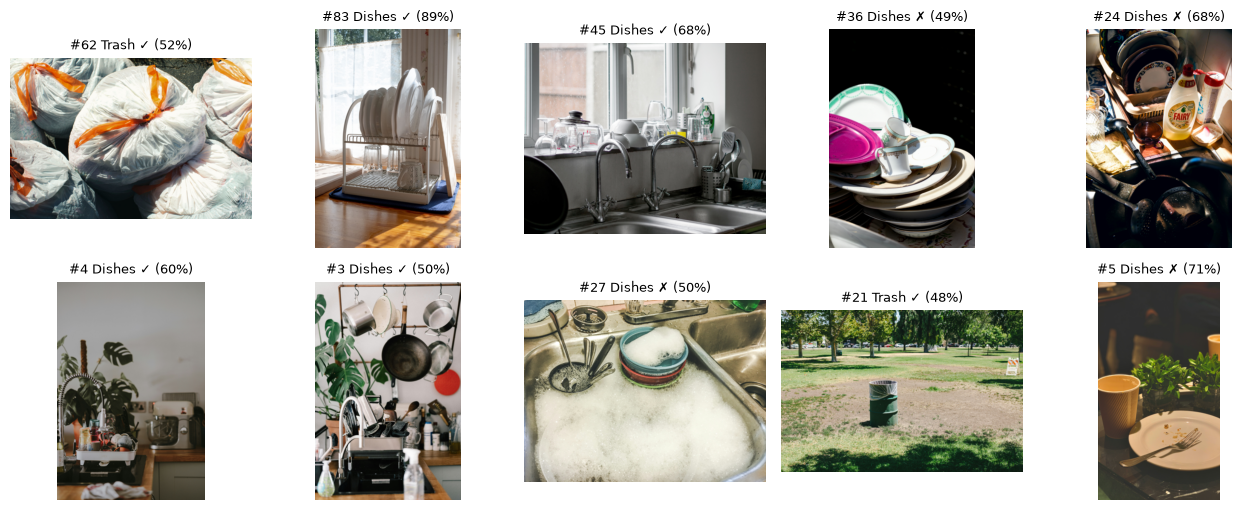

In [21]:
sample = np.random.default_rng(SEED).choice(len(test), 10, replace=False)
show_grid(test.id.values[sample],
          [f"#{test.id.values[i]} {SHORT[proba[i].argmax()]} ({proba[i].max():.0%})" for i in sample])

---
# Phase 9 – Summary and next steps

### What we did
1. Loaded 66 labelled and 36 unlabelled photos and checked the data.
2. Looked at the photos and learned what "complete" and "incomplete" mean in this dataset.
3. Turned every photo into CLIP embeddings from seven views (full, mirror and five crops) with several pre-trained models, plus image-only DINOv2 embeddings.
4. Built a zero-shot baseline from text descriptions.
5. Trained a linear probe, compared models and settings with repeated cross-validation, and blended it with zero-shot.
6. Studied the mistakes and created `submission.csv`.

### Submit
Upload `submission.csv` on the competition page with **Submit Prediction**.

### Ideas to improve
- **Better prompts:** look at the wrong photos in Phase 7 and write descriptions that fit them better.
- **More views:** more or smaller crops can help the model see small details.
- **Fine-tuning:** train the last layers of CLIP. This can be powerful, but with only 66 photos it is easy to overfit, so it must be checked carefully with cross-validation.
- **Ensembles:** average the predictions of several good settings instead of picking only one.